## Question 2 - Search Algorithm Analysis

In [1]:
import time
import tracemalloc
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

### Linear Search

In [2]:
def linear_search(arr, target):
    comparisons = 0

    for i in range(len(arr)):
        comparisons += 1

        if arr[i] == target:
            return i, comparisons

    return -1, comparisons

### Binary Search

In [3]:
def binary_search(arr, target):
    low = 0
    high = len(arr) - 1
    comparisons = 0

    while low <= high:
        mid = (low + high) // 2
        comparisons += 1

        if arr[mid] == target:
            return mid, comparisons

        elif arr[mid] < target:
            low = mid + 1

        else:
            high = mid - 1

    return -1, comparisons

### Generate Dataset

In [4]:
def generate_dataset(size):
    return list(range(size))

### Measure Search Performance

In [5]:
def measure_search(search_function, data, target):
    # Start memory tracking
    tracemalloc.start()

    # Start timer
    start_time = time.perf_counter()

    # Execute search
    result, comparisons = search_function(data, target)

    # Stop timer
    execution_time = time.perf_counter() - start_time

    # Get memory usage
    current_memory, peak_memory = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    return {
        "result": result,
        "comparisons": comparisons,
        "time_sec": execution_time,
        "memory_kb": peak_memory / 1024
    }

### Testing the above code

In [6]:
search_sizes = [100, 1000, 10000, 50000]

search_results = []

for size in search_sizes:

    data = generate_dataset(size)

    # Search for last element
    target = size - 1

    # Linear Search
    linear_result = measure_search(
        linear_search,
        data,
        target
    )

    search_results.append({
        "algorithm": "Linear Search",
        "input_size": size,
        "result": linear_result["result"],
        "comparisons": linear_result["comparisons"],
        "time_sec": linear_result["time_sec"],
        "memory_kb": linear_result["memory_kb"]
    })

    # Binary Search
    binary_result = measure_search(
        binary_search,
        data,
        target
    )

    search_results.append({
        "algorithm": "Binary Search",
        "input_size": size,
        "result": binary_result["result"],
        "comparisons": binary_result["comparisons"],
        "time_sec": binary_result["time_sec"],
        "memory_kb": binary_result["memory_kb"]
    })


search_df = pd.DataFrame(search_results)

search_df

,algorithm,input_size,result,comparisons,time_sec,memory_kb
0,Linear Search,100,99,100,0.000034,0.000000
1,Binary Search,100,99,7,0.000013,0.023438
2,Linear Search,1000,999,1000,0.000919,0.117188
3,Binary Search,1000,999,10,0.000035,0.148438
4,Linear Search,10000,9999,10000,0.003430,0.023438
5,Binary Search,10000,9999,14,0.000016,0.023438
6,Linear Search,50000,49999,50000,0.022281,0.698242
7,Binary Search,50000,49999,16,0.000019,0.023438


## Q3 Code Benchmarking Module

### Single Loop

In [8]:
def single_loop(n):
    total = 0
    operations = 0

    for i in range(n):
        total += i
        operations += 1

    return total, operations

### Nested Loop

In [9]:
def nested_loop(n):
    total = 0
    operations = 0

    for i in range(n):
        for j in range(n):
            total += i + j
            operations += 1

    return total, operations

### Recursive Factorial

In [10]:
def factorial_recursive(n):
    if n <= 1:
        return 1, 1

    result, operations = factorial_recursive(n - 1)

    operations += 1

    return n * result, operations

### Iterative Factorial

In [11]:
def factorial_iterative(n):
    result = 1
    operations = 0

    for i in range(1, n + 1):
        result *= i
        operations += 1

    return result, operations

### Benchmark Function

In [13]:
def benchmark(function, n):
    
    tracemalloc.start()

    start_time = time.perf_counter()

    result, operations = function(n)

    execution_time = time.perf_counter() - start_time

    current_memory, peak_memory = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    return {
        "result": result,
        "operations": operations,
        "time_sec": execution_time,
        "memory_kb": peak_memory / 1024
    }

### testing above code

In [14]:
q3_results = []

# Single Loop
for n in [100, 1000, 10000]:
    
    result = benchmark(single_loop, n)

    q3_results.append({
        "algorithm": "Single Loop",
        "input_size": n,
        "time_sec": result["time_sec"],
        "memory_kb": result["memory_kb"],
        "operations": result["operations"]
    })


# Nested Loop
for n in [100, 500, 1000]:
    
    result = benchmark(nested_loop, n)

    q3_results.append({
        "algorithm": "Nested Loop",
        "input_size": n,
        "time_sec": result["time_sec"],
        "memory_kb": result["memory_kb"],
        "operations": result["operations"]
    })


# Recursive Factorial
for n in [10, 50, 100, 300]:
    
    result = benchmark(factorial_recursive, n)

    q3_results.append({
        "algorithm": "Recursive Factorial",
        "input_size": n,
        "time_sec": result["time_sec"],
        "memory_kb": result["memory_kb"],
        "operations": result["operations"]
    })


# Iterative Factorial
for n in [10, 50, 100, 300]:
    
    result = benchmark(factorial_iterative, n)

    q3_results.append({
        "algorithm": "Iterative Factorial",
        "input_size": n,
        "time_sec": result["time_sec"],
        "memory_kb": result["memory_kb"],
        "operations": result["operations"]
    })


q3_df = pd.DataFrame(q3_results)

q3_df

,algorithm,input_size,time_sec,memory_kb,operations
0,Single Loop,100,0.000040,0.000000,100
1,Single Loop,1000,0.000500,0.000000,1000
2,Single Loop,10000,0.004794,0.023438,10000
3,Nested Loop,100,0.003828,0.023438,10000
4,Nested Loop,500,0.140969,0.698242,250000
5,Nested Loop,1000,0.527929,0.023438,1000000
6,Recursive Factorial,10,0.000016,0.023438,10
7,Recursive Factorial,50,0.000163,0.109375,50
8,Recursive Factorial,100,0.000333,0.195312,100
9,Recursive Factorial,300,0.001837,0.585938,300


In [16]:
print("Code Benchmarking Results")
print("=" * 50)

print(q3_df.to_string(index=False))

Code Benchmarking Results
          algorithm  input_size  time_sec  memory_kb  operations
        Single Loop         100  0.000040   0.000000         100
        Single Loop        1000  0.000500   0.000000        1000
        Single Loop       10000  0.004794   0.023438       10000
        Nested Loop         100  0.003828   0.023438       10000
        Nested Loop         500  0.140969   0.698242      250000
        Nested Loop        1000  0.527929   0.023438     1000000
Recursive Factorial          10  0.000016   0.023438          10
Recursive Factorial          50  0.000163   0.109375          50
Recursive Factorial         100  0.000333   0.195312         100
Recursive Factorial         300  0.001837   0.585938         300
Iterative Factorial          10  0.000011   0.023438          10
Iterative Factorial          50  0.000084   0.109375          50
Iterative Factorial         100  0.000176   0.195312         100
Iterative Factorial         300  0.000598   0.585938         300

## Question 4 - Automated Benchmarking Engine


### Benchmark Engine

In [18]:
class BenchmarkEngine:

    def __init__(self):
        self.results = []

    def run(
        self,
        function,
        input_sizes,
        name=None,
        arg_builder=None
    ):

        if name is None:
            name = function.__name__
            
        if arg_builder is None:
            arg_builder = lambda n: (n,)

        for n in input_sizes:

            # Create function arguments
            args = arg_builder(n)

            # Start memory tracking
            tracemalloc.start()

            # Start timer
            start_time = time.perf_counter()

            # Execute function
            result = function(*args)

            # Stop timer
            execution_time = time.perf_counter() - start_time

            # Get memory
            current_memory, peak_memory = tracemalloc.get_traced_memory()
            tracemalloc.stop()

            # Extract result and operations
            if isinstance(result, tuple) and len(result) == 2:
                actual_result = result[0]
                operations = result[1]

            else:
                actual_result = result
                operations = None
            # Store result
            self.results.append({
                "algorithm": name,
                "input_size": n,
                "time_sec": execution_time,
                "memory_kb": peak_memory / 1024,
                "operations": operations,
                "result": str(actual_result)
            })
        return self

    def get_dataframe(self):
        return pd.DataFrame(self.results)

    def save_csv(self, filename="benchmark_results.csv"):
        df = self.get_dataframe()
        df.to_csv(filename, index=False)
        return df

### RUN THE ENGINE

In [20]:
# Create Benchmark Engine

engine = BenchmarkEngine()

# LINEAR SEARCH

engine.run(
    linear_search,
    [100, 1000, 10000, 50000],
    name="Linear Search",
    arg_builder=lambda n: (list(range(n)), n - 1)
)

# BINARY SEARCH

engine.run(
    binary_search,
    [100, 1000, 10000, 50000],
    name="Binary Search",
    arg_builder=lambda n: (list(range(n)), n - 1)
)

# SINGLE LOOP

engine.run(
    single_loop,
    [100, 1000, 10000, 50000],
    name="Single Loop"
)

# NESTED LOOP

engine.run(
    nested_loop,
    [100, 500, 1000],
    name="Nested Loop"
)

# RECURSIVE FACTORIAL

engine.run(
    factorial_recursive,
    [100, 500, 1000],
    name="Recursive Factorial"
)

# ITERATIVE FACTORIAL

engine.run(
    factorial_iterative,
    [100, 500, 1000],
    name="Iterative Factorial"
)
print("All benchmarks completed!")

All benchmarks completed!


### CREATE THE CSV

In [22]:
benchmark_df = engine.get_dataframe()
print("Benchmark Results")
print("=" * 50)
display(benchmark_df)

Benchmark Results


,algorithm,input_size,time_sec,memory_kb,operations,result
0,Linear Search,100,0.000029,0.000000,100,99
1,Linear Search,1000,0.000968,0.093750,1000,999
2,Linear Search,10000,0.003858,0.023438,10000,9999
3,Linear Search,50000,0.017819,0.023438,50000,49999
4,Binary Search,100,0.000016,0.023438,7,99
5,Binary Search,1000,0.000047,0.179688,10,999
6,Binary Search,10000,0.000036,0.023438,14,9999
7,Binary Search,50000,0.000051,0.023438,16,49999
8,Single Loop,100,0.000035,0.023438,100,4950
9,Single Loop,1000,0.000396,0.023438,1000,499500


In [23]:
benchmark_df.to_csv(
    "benchmark_results.csv",
    index=False
)

print("benchmark_results.csv created successfully!")

benchmark_results.csv created successfully!


## Question 5 - Complexity Analysis Module


In [26]:
complexity_data = {

    "Algorithm": [
        "Linear Search",
        "Binary Search",
        "Recursive Factorial",
        "Iterative Factorial",
        "Single Loop",
        "Nested Loop"
    ],

    "Time Complexity": [
        "O(n)",
        "O(log n)",
        "O(n)",
        "O(n)",
        "O(n)",
        "O(n²)"
    ],

    "Space Complexity": [
        "O(1)",
        "O(1)",
        "O(n)",
        "O(1)",
        "O(1)",
        "O(1)"
    ]
}

complexity_df = pd.DataFrame(complexity_data)
display(complexity_df)

,Algorithm,Time Complexity,Space Complexity
0,Linear Search,O(n),O(1)
1,Binary Search,O(log n),O(1)
2,Recursive Factorial,O(n),O(n)
3,Iterative Factorial,O(n),O(1)
4,Single Loop,O(n),O(1)
5,Nested Loop,O(n²),O(1)


### Theoretical Complexity Table

In [27]:
complexity_data = {

    "Algorithm": [
        "Linear Search",
        "Binary Search",
        "Recursive Factorial",
        "Iterative Factorial",
        "Single Loop",
        "Nested Loop"
    ],

    "Time Complexity": [
        "O(n)",
        "O(log n)",
        "O(n)",
        "O(n)",
        "O(n)",
        "O(n²)"
    ],

    "Space Complexity": [
        "O(1)",
        "O(1)",
        "O(n)",
        "O(1)",
        "O(1)",
        "O(1)"
    ]
}


complexity_df = pd.DataFrame(complexity_data)

display(complexity_df)

,Algorithm,Time Complexity,Space Complexity
0,Linear Search,O(n),O(1)
1,Binary Search,O(log n),O(1)
2,Recursive Factorial,O(n),O(n)
3,Iterative Factorial,O(n),O(1)
4,Single Loop,O(n),O(1)
5,Nested Loop,O(n²),O(1)


### Load Experimental Results

In [29]:
benchmark_df = pd.read_csv(
    "benchmark_results.csv"
)

print("Experimental Results")
print("=" * 50)

display(benchmark_df)

Experimental Results


,algorithm,input_size,time_sec,memory_kb,operations,result
0,Linear Search,100,0.000029,0.000000,100,99
1,Linear Search,1000,0.000968,0.093750,1000,999
2,Linear Search,10000,0.003858,0.023438,10000,9999
3,Linear Search,50000,0.017819,0.023438,50000,49999
4,Binary Search,100,0.000016,0.023438,7,99
5,Binary Search,1000,0.000047,0.179688,10,999
6,Binary Search,10000,0.000036,0.023438,14,9999
7,Binary Search,50000,0.000051,0.023438,16,49999
8,Single Loop,100,0.000035,0.023438,100,4950
9,Single Loop,1000,0.000396,0.023438,1000,499500


### Calculate Average Performance

In [31]:
summary = (
    benchmark_df
    .groupby("algorithm")
    .agg({
        "time_sec": "mean",
        "memory_kb": "mean",
        "operations": "mean"
    })
    .reset_index()
)

summary

,algorithm,time_sec,memory_kb,operations
0,Binary Search,0.000038,0.062500,11.750000
1,Iterative Factorial,0.001295,1.183594,533.333333
2,Linear Search,0.005668,0.035156,15275.000000
3,Nested Loop,0.234774,48.407227,420000.000000
4,Recursive Factorial,0.010380,8.867188,533.333333
5,Single Loop,0.007807,0.041016,15275.000000


### Rename Columns

In [32]:
summary = summary.rename(
    columns={
        "algorithm": "Algorithm",
        "time_sec": "Average Time (sec)",
        "memory_kb": "Average Memory (KB)",
        "operations": "Average Operations"
    }
)

display(summary)

,Algorithm,Average Time (sec),Average Memory (KB),Average Operations
0,Binary Search,0.000038,0.062500,11.750000
1,Iterative Factorial,0.001295,1.183594,533.333333
2,Linear Search,0.005668,0.035156,15275.000000
3,Nested Loop,0.234774,48.407227,420000.000000
4,Recursive Factorial,0.010380,8.867188,533.333333
5,Single Loop,0.007807,0.041016,15275.000000


In [33]:
### Combine Theoretical + Experimental
final_table = complexity_df.merge(
    summary,
    on="Algorithm",
    how="left"
)

display(final_table)

,Algorithm,Time Complexity,Space Complexity,Average Time (sec),Average Memory (KB),Average Operations
0,Linear Search,O(n),O(1),0.005668,0.035156,15275.000000
1,Binary Search,O(log n),O(1),0.000038,0.062500,11.750000
2,Recursive Factorial,O(n),O(n),0.010380,8.867188,533.333333
3,Iterative Factorial,O(n),O(1),0.001295,1.183594,533.333333
4,Single Loop,O(n),O(1),0.007807,0.041016,15275.000000
5,Nested Loop,O(n²),O(1),0.234774,48.407227,420000.000000


### Save Results

In [34]:
final_table.to_csv(
    "complexity_analysis.csv",
    index=False
)

print("complexity_analysis.csv saved successfully!")

complexity_analysis.csv saved successfully!


## Question 6 - Performance Visualization

In [36]:
os.makedirs("graphs", exist_ok=True)
print("graphs folder is ready!")

graphs folder is ready!


### Search Algorithms

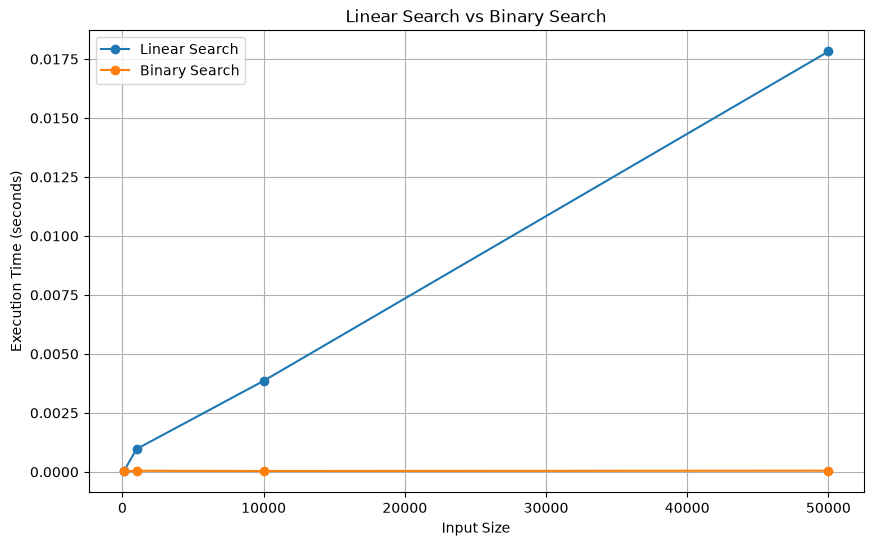

In [37]:
search_data = benchmark_df[
    benchmark_df["algorithm"].isin(
        ["Linear Search", "Binary Search"]
    )
]

plt.figure(figsize=(10, 6))

for algorithm in ["Linear Search", "Binary Search"]:

    data = search_data[
        search_data["algorithm"] == algorithm
    ]

    plt.plot(
        data["input_size"],
        data["time_sec"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Linear Search vs Binary Search")

plt.legend()
plt.grid(True)

plt.savefig(
    "graphs/search_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Factorial

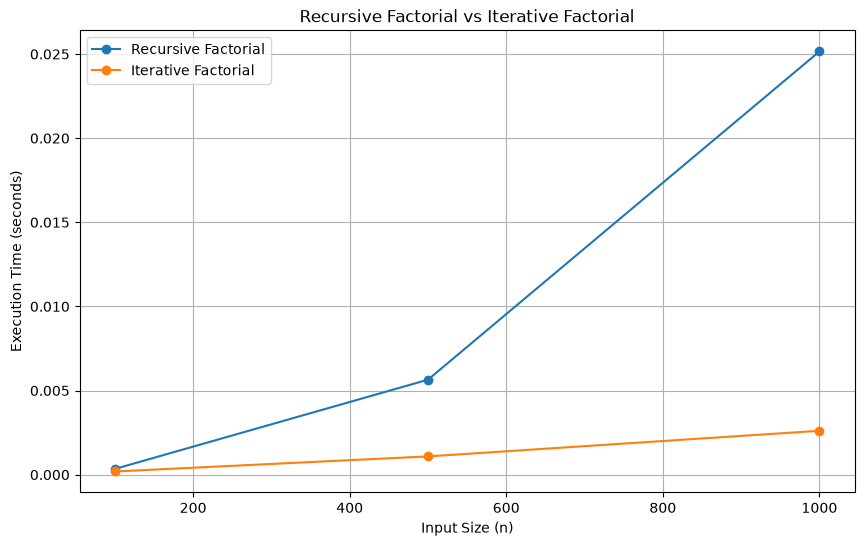

In [38]:
factorial_data = benchmark_df[
    benchmark_df["algorithm"].isin(
        ["Recursive Factorial", "Iterative Factorial"]
    )
]

plt.figure(figsize=(10, 6))

for algorithm in [
    "Recursive Factorial",
    "Iterative Factorial"
]:

    data = factorial_data[
        factorial_data["algorithm"] == algorithm
    ]

    plt.plot(
        data["input_size"],
        data["time_sec"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Recursive Factorial vs Iterative Factorial")

plt.legend()
plt.grid(True)

plt.savefig(
    "graphs/factorial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Loop Comparison

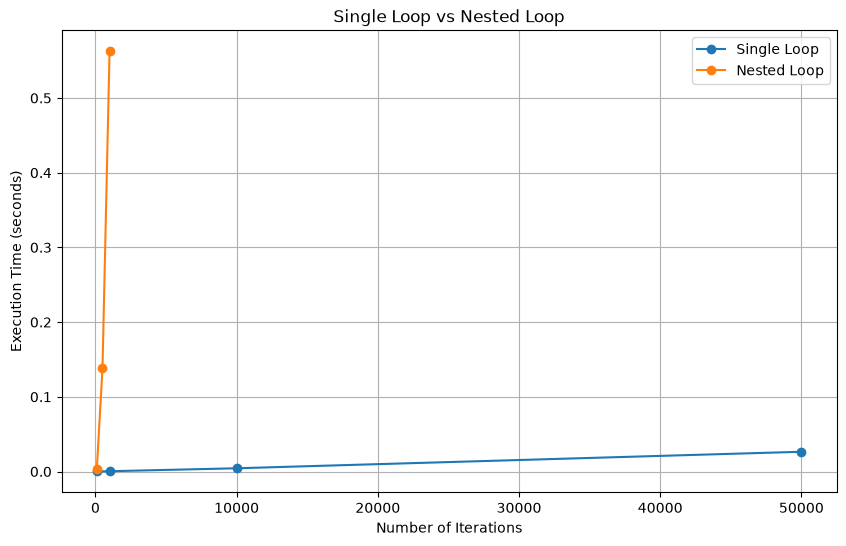

In [40]:
loop_data = benchmark_df[
    benchmark_df["algorithm"].isin(
        ["Single Loop", "Nested Loop"]
    )
]

plt.figure(figsize=(10, 6))

for algorithm in [
    "Single Loop",
    "Nested Loop"
]:

    data = loop_data[
        loop_data["algorithm"] == algorithm
    ]

    plt.plot(
        data["input_size"],
        data["time_sec"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Number of Iterations")
plt.ylabel("Execution Time (seconds)")
plt.title("Single Loop vs Nested Loop")

plt.legend()
plt.grid(True)

plt.savefig(
    "graphs/loop_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()